# 02 — Features RFM

**Entrada:** `data/processed/transactions_clean.csv` (saída do notebook 01)
**Saída:** tabela RFM por cliente, versão transformada e padronizada para clusterização

**O que é RFM**
- **Recency (Recência):** há quantos dias o cliente comprou pela última vez (menor é melhor)
- **Frequency (Frequência):** quantas notas fiscais distintas o cliente tem (maior é melhor)
- **Monetary (Valor):** quanto o cliente gastou no total (maior é melhor)

**Objetivos deste notebook**
1. Construir a tabela RFM, uma linha por cliente, com data de referência fixa
2. Analisar distribuição e assimetria de cada variável
3. Aplicar log e padronização para preparar a clusterização
4. Criar uma **segmentação por regras** (baseline) para comparar depois com K-Means, DBSCAN e GMM

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path("..").resolve()))
from src.rfm import build_rfm, rfm_scores, rule_based_segment

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

## 2. Carga

In [2]:
df = pd.read_csv(
    PROCESSED / "transactions_clean.csv",
    parse_dates=["InvoiceDate"],
    dtype={"Invoice": str, "StockCode": str},
)
print(f"{len(df):,} linhas | {df['CustomerID'].nunique():,} clientes")
print(f"Período: {df['InvoiceDate'].min():%d/%m/%Y} a {df['InvoiceDate'].max():%d/%m/%Y}")

776,840 linhas | 5,853 clientes
Período: 01/12/2009 a 09/12/2011


## 3. Tabela RFM

A **data de referência** (snapshot) é o dia seguinte à última compra da base. Fixar essa data é importante: se usássemos a data de hoje, todos os clientes pareceriam "inativos" porque o dataset é antigo.

In [3]:
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Data de referência:", snapshot_date.date())

rfm = build_rfm(df, snapshot_date)
rfm.head()

Data de referência: 2011-12-10


,Recency,Frequency,Monetary
CustomerID,,,
12346,325,12,"77,556.46"
12347,2,8,"4,921.53"
12348,75,5,"1,658.40"
12349,18,3,"3,678.69"
12350,310,1,294.40


In [4]:
rfm.describe()

,Recency,Frequency,Monetary
count,"5,853.00","5,853.00","5,853.00"
mean,199.78,6.26,"2,918.52"
std,208.54,12.76,"14,335.51"
min,0.00,1.00,2.95
25%,25.00,1.00,340.85
50%,95.00,3.00,856.03
75%,379.00,7.00,"2,240.90"
max,738.00,375.00,"580,987.04"


## 4. Distribuição e assimetria

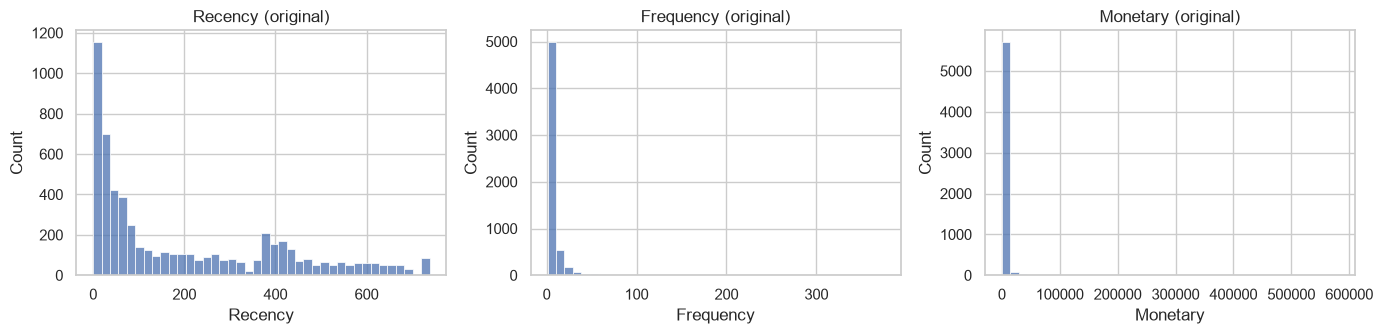

,assimetria (skew)
Recency,0.89
Frequency,12.08
Monetary,25.29


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, rfm.columns):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"{col} (original)")
plt.tight_layout()
plt.show()

rfm.skew().to_frame("assimetria (skew)")

Frequência e valor monetário têm cauda longa à direita: poucos clientes concentram muitas compras e muito dinheiro. Algoritmos baseados em distância (K-Means) e em distribuições gaussianas (GMM) são sensíveis a isso. A solução padrão é o **log**.

## 5. Transformação log e padronização

1. `log1p` em cada variável, para reduzir a assimetria
2. `StandardScaler` (média 0, desvio 1), para que nenhuma variável domine a distância só por estar em escala maior

In [6]:
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    index=rfm.index,
    columns=rfm.columns,
)

comparacao = pd.DataFrame({"antes": rfm.skew(), "depois do log": rfm_log.skew()})
comparacao

,antes,depois do log
Recency,0.89,-0.55
Frequency,12.08,1.00
Monetary,25.29,0.27


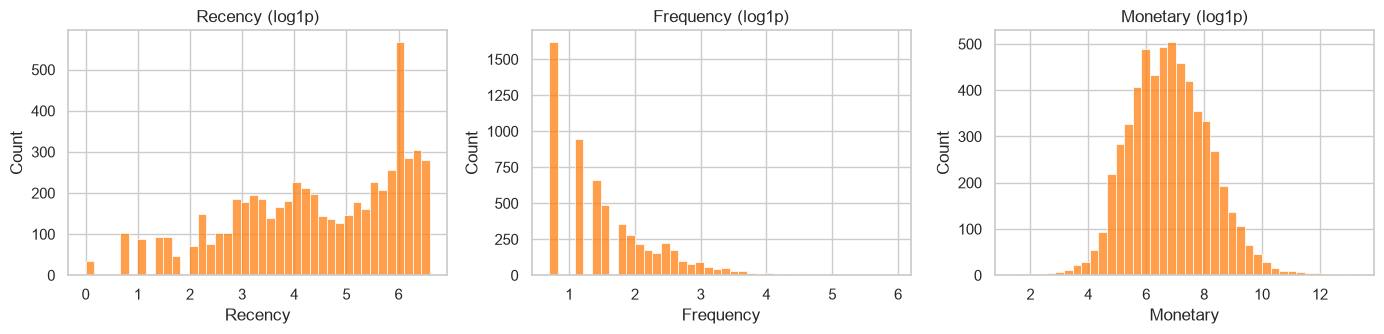

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, rfm_log.columns):
    sns.histplot(rfm_log[col], bins=40, ax=ax, color="tab:orange")
    ax.set_title(f"{col} (log1p)")
plt.tight_layout()
fig.savefig(FIGURES / "02_distribuicao_rfm_log.png", dpi=150)
plt.show()

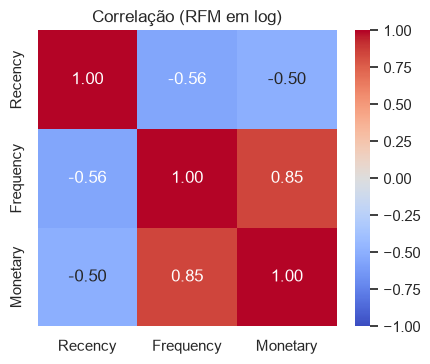

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(rfm_log.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação (RFM em log)")
plt.tight_layout()
fig.savefig(FIGURES / "02_correlacao_rfm.png", dpi=150)
plt.show()

Frequência e valor monetário costumam ser **fortemente correlacionados** (quem compra mais vezes gasta mais). Isso é esperado e vale comentar no README: as duas variáveis carregam informação parecida, e a recência acrescenta a dimensão de tempo.

## 6. Outliers

Antes de decidir o que fazer, vale olhar os maiores clientes.

In [9]:
rfm.sort_values('Monetary', ascending=False).head(10)

,Recency,Frequency,Monetary
CustomerID,,,
18102,0,145,"580,987.04"
14646,1,145,"526,751.52"
14156,9,145,"304,719.88"
14911,1,375,"279,477.79"
17450,8,51,"244,784.25"
13694,3,143,"195,640.69"
17511,2,60,"172,132.87"
16446,0,2,"168,472.50"
16684,4,55,"147,142.77"


Clientes muito acima da média podem ser **atacadistas**, e não consumidores finais. Nesta etapa eu **mantenho** todos: no log eles ficam bem menos extremos, e na clusterização vou ver se formam um grupo próprio (o DBSCAN também consegue marcá-los como ruído).

## 7. Baseline: segmentação por regras

Antes de usar machine learning, criamos uma segmentação simples por **notas de 1 a 5** (quintis) em cada dimensão. Esse baseline serve para comparar: o K-Means precisa encontrar algo mais útil do que regras simples.

In [10]:
scores = rfm_scores(rfm)
scores["Segmento_regra"] = rule_based_segment(scores)
scores.head()

,Recency,Frequency,Monetary,R,F,M,RFM_score,Segmento_regra
CustomerID,,,,,,,,
12346,325,12,"77,556.46",2,5,5,12,Em risco
12347,2,8,"4,921.53",5,4,5,14,Campeões
12348,75,5,"1,658.40",3,4,4,11,Leais
12349,18,3,"3,678.69",5,3,5,13,Leais
12350,310,1,294.40,2,1,2,5,Hibernando


In [11]:
perfil = (
    scores.groupby("Segmento_regra")
    .agg(
        clientes=("Recency", "size"),
        recencia_media=("Recency", "mean"),
        frequencia_media=("Frequency", "mean"),
        valor_medio=("Monetary", "mean"),
        valor_total=("Monetary", "sum"),
    )
    .assign(pct_clientes=lambda d: d["clientes"] / d["clientes"].sum() * 100)
    .assign(pct_receita=lambda d: d["valor_total"] / d["valor_total"].sum() * 100)
    .sort_values("valor_total", ascending=False)
)
perfil[["clientes", "pct_clientes", "recencia_media", "frequencia_media", "valor_medio", "pct_receita"]]

,clientes,pct_clientes,recencia_media,frequencia_media,valor_medio,pct_receita
Segmento_regra,,,,,,
Campeões,1462,24.98,19.51,15.62,"8,052.24",68.92
Leais,1221,20.86,77.40,5.39,"2,026.69",14.49
Em risco,829,14.16,367.34,5.00,"1,925.39",9.34
Hibernando,1512,25.83,455.97,1.25,410.88,3.64
Novos,447,7.64,27.40,1.47,921.29,2.41
Potenciais,382,6.53,104.99,1.36,539.01,1.21


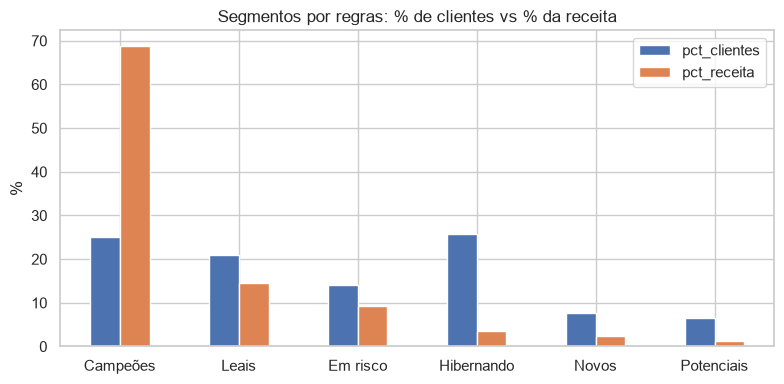

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
perfil[["pct_clientes", "pct_receita"]].plot.bar(ax=ax)
ax.set_title("Segmentos por regras: % de clientes vs % da receita")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(FIGURES / "02_segmentos_regra.png", dpi=150)
plt.show()

## 8. Salvando

In [13]:
rfm.to_csv(PROCESSED / "rfm.csv")
rfm_scaled.to_csv(PROCESSED / "rfm_scaled.csv")
scores.to_csv(PROCESSED / "rfm_scores.csv")
print("Salvos: rfm.csv, rfm_scaled.csv, rfm_scores.csv")
print(f"Clientes: {len(rfm):,}")

Salvos: rfm.csv, rfm_scaled.csv, rfm_scores.csv
Clientes: 5,853


## Conclusões e próximos passos

- Anote aqui: a assimetria antes/depois do log, a correlação entre Frequência e Valor, e qual segmento por regras concentra mais receita.
- **Próximo notebook (`03_clusterizacao.ipynb`):** rodar K-Means, DBSCAN e GMM em `rfm_scaled.csv`, escolher o número de clusters e comparar com silhouette e Davies-Bouldin.